In [ ]:

from deap import base, creator, gp, tools
import matplotlib.pyplot as pyplot
import numpy as np
import pickle
import random
import operator
import multiprocessing as mp
from Dataloader.dataloader import load_nslkdd as load_data
from sklearn import tree

creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

CXPB, MUTPB, NGEN = 0.8, 1/41, 100
NRUNS = 30
TOURNSIZE = 3
IND_SIZE = 41

POPCOUNT = 100




/Users/armindelmo/Library/Python/3.9/lib/python/site-packages/deap/creator.py:185: RuntimeWarning: A class named 'FitnessMax' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "
/Users/armindelmo/Library/Python/3.9/lib/python/site-packages/deap/creator.py:185: RuntimeWarning: A class named 'Individual' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "


In [ ]:
# Simulated Annealing Parameters
TEMP = 1.0 # gets a 10% deduction every generation via cooling rate
COOLING_RATE = 0.9 # applied once a generation
ITER_PER_OFFSPRING = 3

# Dataloader
We'll need to wait on Benny to finish up his dataloader to do this

In [ ]:
data = load_data(binary_labels=True, scale=True)

# Define Individuals

We are using complex sets to collect the decisions of the individuals

In [ ]:
toolbox = base.Toolbox()
# tree selection
toolbox.register("attr_bool", random.randint, 0, 1)

toolbox.register("individual", tools.initRepeat, creator.Individual, 
                 toolbox.attr_bool, IND_SIZE)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

toolbox.register("mate", tools.cxOnePoint)
toolbox.register("mutate", tools.mutFlipBit, indpb = MUTPB)
toolbox.register("select", tools.selTournament, tournsize=3)


# Evaluation Formulas
Calculate the haversine distance of the whole path they took.

In [ ]:
FEATURE_NAMES = data["feature_names"]
X_train = data["X_train"].to_numpy(dtype=float)
y_train = data["y_train"].to_numpy(dtype=int)
X_val = data["X_val"].to_numpy(dtype=float) if len(data["X_val"]) else None
y_val = data["y_val"].to_numpy(dtype=int) if len(data["y_val"]) else None
X_test = data["X_test"].to_numpy(dtype=float)
y_test = data["y_test"].to_numpy(dtype=int)

# only use the training set, as we will measure accuracy via testing set in the end
def training_accuracy(individual):
    ind = np.array(individual, dtype=bool)

    filtered = X_train[:, ind]

    # generate a decision tree using scikit-learn, no forest
    clf = tree.DecisionTreeClassifier(random_state=30)
    clf.fit(filtered, y_train)

    return clf.score(filtered, y_train)

def testing_accuracy(individual):
    
    # discard solutions that remove all features
    if(np.sum(individual) == 0):
        return 0.0
    
    ind = np.array(individual, dtype=bool)

    filtered_train = X_train[:, ind]
    filtered_test = X_test[:, ind]

    # generate a decision tree using scikit-learn, no forest
    clf = tree.DecisionTreeClassifier(random_state=30)
    clf.fit(filtered_train, y_train)

    return clf.score(filtered_test, y_test)

def evaluate_tree(individual):
    ind = np.array(individual, dtype=bool)
    if not ind.any():
        return 0.0, 0.0
    
    X_train_selection = X_train[:, ind]
    X_test_selection = X_test[:, ind]

    clf = tree.DecisionTreeClassifier(random_state=30)
    clf.fit(X_train_selection, y_train)

    train_acc = clf.score(X_train_selection, y_train)
    test_acc = clf.score(X_test_selection, y_test)

    return train_acc, test_acc

# count how many arguments we use
def count_features(individual):
    return int(np.count_nonzero(individual))

def fitness_evaluation(individual):
    train_acc, test_acc = evaluate_tree(individual)

    individual.train_acc = train_acc
    individual.test_acc = test_acc

    features_selected = count_features(individual)
    return ((0.8 * test_acc + 0.2 * (1 - features_selected / IND_SIZE)),)

In [ ]:
def get_neighbor(individual):
    neighbor = toolbox.clone(individual)
    neighbor, = toolbox.mutate(neighbor)
    
    if neighbor.fitness.valid:
        del neighbor.fitness.values
    return neighbor

def simulate_annealing(individual, temp):

    current = toolbox.clone(individual)
    if not current.fitness.valid:
        current.fitness.values = toolbox.evaluate(current)

    current_score = current.fitness.values[0]
    best = toolbox.clone(current)
    best_score = current_score

    for _ in range(ITER_PER_OFFSPRING):
        candidate = get_neighbor(current)
        candidate_score = toolbox.evaluate(candidate)[0]

        diff = candidate_score - current_score  # maximize
        prob = np.exp((diff / temp))
        accept = diff > 0 or random.random() < prob

        if accept:
            current = candidate
            current_score = candidate_score
            if current_score > best_score:
                best = toolbox.clone(current)
                best_score = current_score

    best.fitness.values = (best_score,)
    return best

toolbox.register("simulate_annealing", simulate_annealing)

In [ ]:
# following is meant to store the data of our runs
training_stats = tools.Statistics(lambda ind: ind.fitness.values[0])
training_stats.register("avg", np.mean, axis=0)
training_stats.register("std", np.std, axis=0)
training_stats.register("min", np.min, axis=0)
training_stats.register("max", np.max, axis=0)

# hold data of the testing runs
test_stats = tools.Statistics(lambda ind: getattr(ind, "test_acc", 0.0))
test_stats.register("avg", np.mean, axis=0)
test_stats.register("std", np.std, axis=0)
test_stats.register("min", np.min, axis=0)
test_stats.register("max", np.max, axis=0)

stats = tools.MultiStatistics(train = training_stats, test = test_stats)

In [ ]:
# Meant to return the completion of the run to see if things are going well

def completion(logbook):
    final_train = logbook.chapters["train"][-1]
    final_test = logbook.chapters["test"][-1]

    train_mean = final_train["avg"]
    test_mean = final_test["avg"]

    train_ci = 1.96 * final_train["std"] / np.sqrt(POPCOUNT)
    test_ci = 1.96 * final_test["std"] / np.sqrt(POPCOUNT)

    print(
        f"Completed a simulation | "
        f"Train Mean: {train_mean:.4f}, 95% CI: [{train_ci}]"
        f"Test Mean: {test_mean:.4f}, 95% CI: [{test_ci}]"
    )

    return

# Simulation Function
There are two genetic loops present, the first one is the hybrid model with simulated annealing, while the next one isn't so.

These will run and be pickled in order to collect data.

In [ ]:
last_gen_genome = []
last_gen_acc = []
def run_sim_hybrid(_):
    random.seed(_)

    temp = TEMP
    hof = tools.HallOfFame(1)
    pop = toolbox.population(n=POPCOUNT)

    # initial evaluation
    invalid = [ind for ind in pop if not ind.fitness.valid]
    fitnesses = map(toolbox.evaluate, invalid)
    for ind, fit in zip(invalid, fitnesses):
        ind.fitness.values = fit

    logbook = tools.Logbook()
    for g in range(NGEN):
        # always ensure validity before stats
        invalid = [ind for ind in pop if not ind.fitness.valid]
        fitnesses = map(toolbox.evaluate, invalid)
        for ind, fit in zip(invalid, fitnesses):
            ind.fitness.values = fit

        record = stats.compile(pop)
        best_ind = tools.selBest(pop, 1)[0]
        logbook.record(gen=g, best_ind=best_ind[:], **record)

        offspring = list(map(toolbox.clone, toolbox.select(pop, len(pop))))

        for child1, child2 in zip(offspring[::2], offspring[1::2]):
            if random.random() < CXPB:
                toolbox.mate(child1, child2)
                del child1.fitness.values
                del child2.fitness.values

        for mutant in offspring:
            if random.random() < MUTPB:
                toolbox.mutate(mutant)
                del mutant.fitness.values

        invalid = [ind for ind in offspring if not ind.fitness.valid]
        fitnesses = map(toolbox.evaluate, invalid)
        for ind, fit in zip(invalid, fitnesses):
            ind.fitness.values = fit
            
        # simulated annealing
        offspring = [toolbox.simulate_annealing(ind, temp) for ind in offspring]

        pop[:] = offspring


        hof.update(pop)

        # elitism
        if len(hof) > 0:
            worst_index = min(range(len(pop)), key=lambda i: pop[i].fitness.values[0])
            pop[worst_index] = hof[0]  
        
        temp *= COOLING_RATE
            

    last_gen_test_accs = [getattr(ind, "test_acc", testing_accuracy(ind)) for ind in pop]
    completion(logbook)
    return logbook, hof, pop, last_gen_test_accs

In [ ]:
def run_sim_simple(_):
    random.seed(_)

    hof = tools.HallOfFame(1)
    pop = toolbox.population(n=POPCOUNT)

    # initial evaluation
    invalid = [ind for ind in pop if not ind.fitness.valid]
    fitnesses = map(toolbox.evaluate, invalid)
    for ind, fit in zip(invalid, fitnesses):
        ind.fitness.values = fit

    logbook = tools.Logbook()
    for g in range(NGEN):
        # always ensure validity before stats
        invalid = [ind for ind in pop if not ind.fitness.valid]
        fitnesses = map(toolbox.evaluate, invalid)
        for ind, fit in zip(invalid, fitnesses):
            ind.fitness.values = fit

        record = stats.compile(pop)
        best_ind = tools.selBest(pop, 1)[0]
        logbook.record(gen=g, best_ind=best_ind[:], **record)

        offspring = list(map(toolbox.clone, toolbox.select(pop, len(pop))))

        for child1, child2 in zip(offspring[::2], offspring[1::2]):
            if random.random() < CXPB:
                toolbox.mate(child1, child2)
                del child1.fitness.values
                del child2.fitness.values

        for mutant in offspring:
            if random.random() < MUTPB:
                toolbox.mutate(mutant)
                del mutant.fitness.values

        invalid = [ind for ind in offspring if not ind.fitness.valid]
        fitnesses = map(toolbox.evaluate, invalid)
        for ind, fit in zip(invalid, fitnesses):
            ind.fitness.values = fit

        pop[:] = offspring

        hof.update(pop)

        
        # elitism
        if len(hof) > 0:
            worst_index = min(range(len(pop)), key=lambda i: pop[i].fitness.values[0])
            pop[worst_index] = hof[0]  


    last_gen_test_accs = [getattr(ind, "test_acc", testing_accuracy(ind)) for ind in pop]

    completion(logbook)
    return logbook, hof, pop, last_gen_test_accs

# Recording all the Information
The following codeblock holds the function we will use to compile all 50 runs for each problem representation.
We collect the best individual out of each iteration, and use it for a graph shown in the paper.

In [ ]:
def combine_logbooks(all_logbooks, l_gen_test_accs, pops):
    max_gen = min(len(lb.chapters["train"]) for lb in all_logbooks)
    n_runs = len(all_logbooks)
    
    combined_books = {
        "train": {
            "gen": np.arange(max_gen),
            "avg_mean": [],
            "avg_ci": [],
            "best_mean": [],
            "best_ci": [],
        },
        "test": {
            "gen": np.arange(max_gen),
            "avg_mean": [],
            "avg_ci": [],
            "best_mean": [],
            "best_ci": [],
        },
        "misc": {
            "last_gen_accs": [],
            "pop_features": []
        }
    }
    combined_books["misc"]["last_gen_accs"].append(np.array(l_gen_test_accs))

    feature_count = [[count_features(ind) for ind in pop] for pop in pops]
    combined_books["misc"]["pop_features"] = feature_count
    
    for gen_index in range(max_gen):
        train_avg_fitness, test_avg_fitness = [], []
        train_best_fitness, test_best_fitness = [], []

        for lb in all_logbooks:
            train_rec = lb.chapters["train"][gen_index]
            test_rec = lb.chapters["test"][gen_index]

            train_avg_fitness.append(train_rec["avg"])
            train_best_fitness.append(train_rec["max"])
            test_avg_fitness.append(test_rec["avg"])
            test_best_fitness.append(test_rec["max"])

        # turn into arrays; testing logic
        train_avg_fitness = np.array(train_avg_fitness)
        train_best_fitness = np.array(train_best_fitness)

        test_avg_fitness = np.array(test_avg_fitness)
        test_best_fitness = np.array(test_best_fitness)
        # means
        combined_books["train"]["avg_mean"].append(np.mean(train_avg_fitness))
        combined_books["train"]["best_mean"].append(np.mean(train_best_fitness))

        combined_books["test"]["avg_mean"].append(np.mean(test_avg_fitness))
        combined_books["test"]["best_mean"].append(np.mean(test_best_fitness))

        # ci's
        combined_books["train"]["avg_ci"].append(1.96 * np.std(train_avg_fitness, ddof=1) / np.sqrt(n_runs))
        combined_books["train"]["best_ci"].append(1.96 * np.std(train_best_fitness, ddof=1) / np.sqrt(n_runs))

        combined_books["test"]["avg_ci"].append(1.96 * np.std(test_avg_fitness, ddof=1) / np.sqrt(n_runs))
        combined_books["test"]["best_ci"].append(1.96 * np.std(test_best_fitness, ddof=1) / np.sqrt(n_runs))
        
    return combined_books

    

# Approaches
The following approaches will be done in each coding block


## Simple Representation
No simulated annealing was used here in order to find solutions. 

In [ ]:
mp.set_start_method("fork", force=True)

_ = None
toolbox.register("evaluate", fitness_evaluation)

results = None
with mp.Pool() as pool:
   results = pool.map(run_sim_simple, range(NRUNS))
    
# exporting all the information to use for graphing
logbooks, hofs, pops, last_gen_test_accs = zip(*results)


logbook_compiled = combine_logbooks(logbooks, last_gen_test_accs, pops)
# put in where your logbooks saved
with open("/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/compiled_logbooks_simple.pkl", 'wb') as file:
    pickle.dump(logbook_compiled, file)
        
with open("/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/hof_simple.pkl", 'wb') as file:
    pickle.dump(hofs, file)

with open("/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/pop_simple.pkl", 'wb') as file:
    pickle.dump(pops, file)

with open("/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/last_acc_simple.pkl", 'wb') as file:
    pickle.dump(last_gen_acc, file)

#*/

# Hybrid Approach
Uses simulated annealing to go around search space

In [ ]:
mp.set_start_method("fork", force=True)

_ = None
toolbox.register("evaluate", fitness_evaluation)

results = None
with mp.Pool() as pool:
   results = pool.map(run_sim_hybrid, range(NRUNS))
    
# exporting all the information to use for graphing
logbooks, hofs, pops, last_gen_test_accs = zip(*results)


logbook_compiled = combine_logbooks(logbooks, last_gen_test_accs, pops)
# put in where your logbooks saved
with open("/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/compiled_logbooks_hybrid.pkl", 'wb') as file:
    pickle.dump(logbook_compiled, file)
        
with open("/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/hof_hybrid.pkl", 'wb') as file:
    pickle.dump(hofs, file)

with open("/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/pop_hybrid.pkl", 'wb') as file:
    pickle.dump(pops, file)

with open("/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/last_acc_hybrid.pkl", 'wb') as file:
    pickle.dump(last_gen_acc, file)
#*/

# Plot Graphs
Running the code to build the graphs for the assignment.

In [6]:
def plot_graph(title, x_label, y_label, datafile_path, save_graph, graph_type, type):
    gen = range(1, NGEN + 1)

    data = None
    with open(datafile_path, 'rb') as file:
        data = pickle.load(file)
        
    avg = np.array(data[graph_type][f"{type}_mean"])
    ci = np.array(data[graph_type][f"{type}_ci"])
    

    pyplot.figure()
    
    pyplot.plot(gen, avg, label="representation", color="blue")
    pyplot.fill_between(gen, avg - ci, avg + ci, alpha = 0.2, label="95% ci", color="red")
        
    # beautifying the graph
    pyplot.title(title)
    pyplot.xlabel(x_label)
    pyplot.ylabel(y_label)
    pyplot.locator_params(axis='y', nbins=20)
    # display legend
    pyplot.legend()
    
    if save_graph:
        pyplot.savefig(f"{title}.png", dpi = 500)
        pyplot.close()
    else:   
        pyplot.show()
simple_path = "/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/compiled_logbooks_simple.pkl"
hybrid_path = "/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/compiled_logbooks_hybrid.pkl"
#andkeys_path = "/Users/armindelmo/Documents/UCF-CAP5512-Evolutionary-Computation/HW3/compiled_logbooks_randkeys.pkl"

def plot_all_graphs(names, paths, graph_types):
    for i in range(len(paths)):
        for j in range(len(graph_types)):
            plot_graph(f"{names[i]}-{graph_types[j]} n = 200, mean", "generation", "% accuracy", paths[i], True, graph_types[j], "avg")
            plot_graph(f"{names[i]}-{graph_types[j]} n = 200, best", "generation", "% accuracy", paths[i], True, graph_types[j], "best")

plot_all_graphs(["simple", "hybrid"], [simple_path, hybrid_path], ["train", "test"])


In [ ]:
# the following plots all of the graphs against each other.
def plot_multigraph(title, x_label, y_label, datafile_paths, names, save_graph, graph_types, type):
       
    pyplot.figure()
    
    # iterate through all of the pickles
    for path in datafile_paths:
        gen = range(1, NGEN + 1)
    
        data = None
        with open(path, 'rb') as file:
            data = pickle.load(file)
        for graph_type in graph_types:

            avg = np.array(data[graph_type][f"{type}_mean"])
            ci = np.array(data[graph_type][f"{type}_ci"])
        
            pyplot.plot(gen, avg, label=f"{names[datafile_paths.index(path)]}-{graph_type}")
            pyplot.fill_between(gen, avg - ci, avg + ci, alpha = 0.2, label="95% ci")
        
    # beautifying the graph
    pyplot.title(title)
    pyplot.xlabel(x_label)
    pyplot.ylabel(y_label)
    
    # display legend
    pyplot.legend()
    
    if save_graph:
        pyplot.savefig(f"{title}.png", dpi = 300)
        pyplot.close()
    else:   
        pyplot.show()

all_paths = [simple_path, hybrid_path]
names = ["Simple", "Hybrid"]

plot_multigraph("GA + Hybrid GA, n = 200, 50 runs averages", "generation", "% accuracy", all_paths, names, True, ["train", "test"], "avg")
plot_multigraph("GA + Hybrid GA, n = 200, 50 runs bests", "generation", "% accuracy", all_paths, names, True, ["train", "test"], "best")


# Box and Whisker Plots
These plots are responsible for showing the variability of each algorith we ended up using.
Particularly, we want to show the quartiles of data that we have present.

In [9]:
# box and whisker
def box_whisker(title, x_label, y_label, datafile_path, save_graph, graph_type, type):

    path = None
    with open(datafile_path, 'rb') as file:
        path = pickle.load(file)

    data = np.array(path["misc"][graph_type])
    data = data.flatten()

    pyplot.boxplot(data, label="Run")

    pyplot.title(title)
    pyplot.xlabel(x_label)
    pyplot.ylabel(y_label)
    


    if save_graph:
        pyplot.savefig(f"{title}-boxplot.png", dpi=300)
        pyplot.close()
    else:
        pyplot.show()

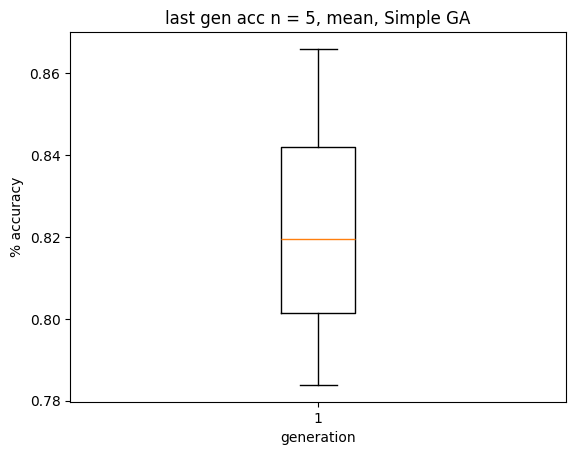

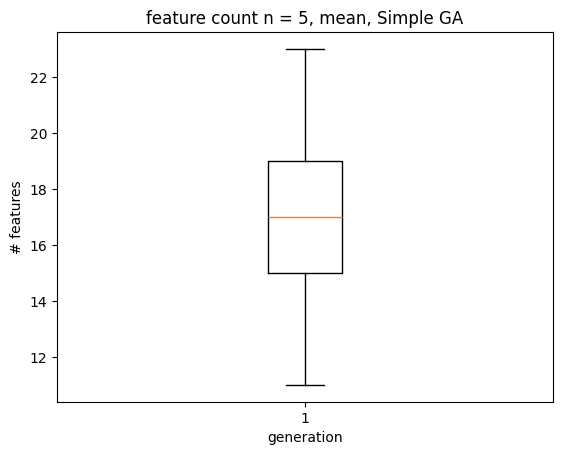

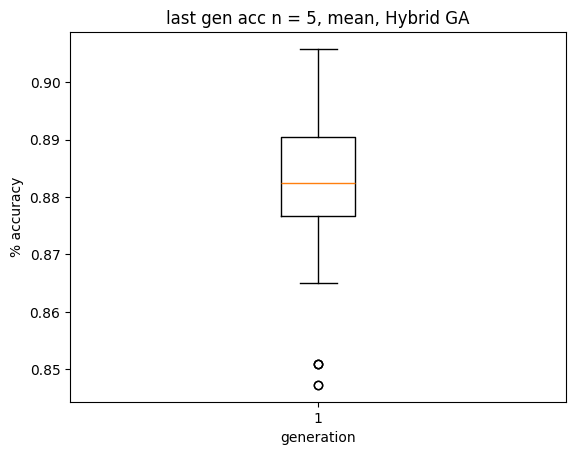

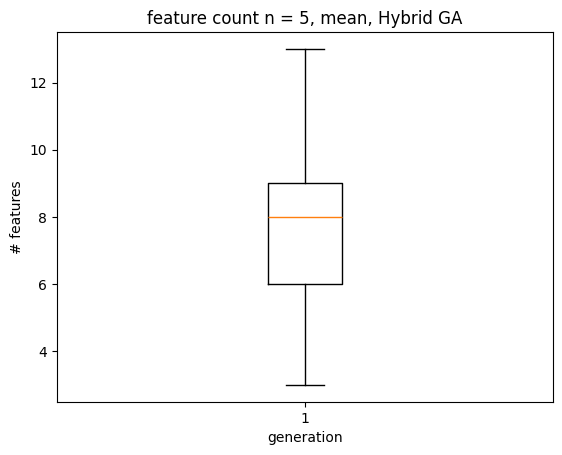

In [11]:
# plot_graph(f"{names[i]}-{graph_types[j]} n = 200, mean", "generation", "% accuracy", paths[i], True, graph_types[j], "avg")
box_whisker(f"last gen acc n = {POPCOUNT}, mean, Simple GA", "generation", "% accuracy", simple_path, False, "last_gen_accs", "avg")
box_whisker(f"feature count n = {POPCOUNT}, mean, Simple GA", "generation", "# features", simple_path, False, "pop_features", "avg")
box_whisker(f"last gen acc n = {POPCOUNT}, mean, Hybrid GA", "generation", "% accuracy", hybrid_path, False, "last_gen_accs", "avg")
box_whisker(f"feature count n = {POPCOUNT}, mean, Hybrid GA", "generation", "# features", hybrid_path, False, "pop_features", "avg")